# Processed Data Characterization and Exploratory Data Analysis

This notebook characterizes the prepared data for Lisbon and Porto: Airbnb listings and reviews, OpenStreetMap (OSM) points of interest, Wikipedia articles, and the spatially enriched listing files. It covers volumes, missing values, distributions, spatial coverage, text lengths, and document-level metrics. Tables are exported as CSV and figures as PDF.

**Scope:** the current `data/processed/` directory contains prepared source records and enriched listings, but no separate consolidated final search-document corpus. Text metrics therefore describe one processed listing, review, POI, or Wikipedia article per document proxy. If a consolidated corpus is added later, its schema can be profiled in this notebook too.

**How to run:** execute from the repository root. All inputs come from `data/processed/`; outputs are written to `analysis/tables/processed/` and `analysis/figures/processed/` so they stay separate from the raw-data EDA.

## 1. Setup and load processed inputs

In [1]:
from collections import Counter
from pathlib import Path
import html
import json
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")

candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
ROOT = next((path for path in candidates if (path / "data/processed/airbnb").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Could not find data/processed/airbnb from the current directory or its parents.")

PROCESSED = ROOT / "data" / "processed"
TABLES = ROOT / "analysis" / "tables" / "processed"
FIGURES = ROOT / "analysis" / "figures" / "processed"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
CITIES = ["lisboa", "porto"]
SEED = 42

listings = {
    city: pd.read_csv(PROCESSED / "airbnb" / f"{city}_listings.csv.gz", compression="gzip", low_memory=False)
    for city in CITIES
}
spatial_listings = {
    city: pd.read_csv(PROCESSED / "spatial" / "airbnb" / f"{city}_listings_spatial.csv.gz", compression="gzip", low_memory=False)
    for city in CITIES
}
osm = {
    city: pd.read_csv(PROCESSED / "osm" / f"pois_{city}.csv.gz", compression="gzip", low_memory=False)
    for city in CITIES
}
wikipedia = pd.read_json(PROCESSED / "wikipedia" / "articles.jsonl", lines=True)
prepared_report = json.loads((PROCESSED / "characterization.json").read_text(encoding="utf-8"))
spatial_report_path = PROCESSED / "spatial" / "spatial_characterization.json"
spatial_report = json.loads(spatial_report_path.read_text(encoding="utf-8")) if spatial_report_path.exists() else {}

print(f"Project root: {ROOT}")
print(f"Prepared data report generated: {prepared_report.get('generated_at_utc', 'unknown')}")
print(f"Spatial scope: {spatial_report.get('scope_note', 'No spatial characterization note found.')}")

Project root: C:\Users\ASUS\Desktop\PRI_projeto
Prepared data report generated: 2026-10-09T09:21:52.581829+00:00
Spatial scope: Listings are retained, not clipped to city limits. GeoJSON groups identify the municipality each listing falls in. Nearest distances use the POIs in the downloaded Overpass bounding-box extract for that city; they are not guaranteed to represent every POI in OpenStreetMap.


## 2. Source volumes and document text metrics

Reviews are streamed in chunks to keep memory use manageable. Length summaries are computed for all processed records. Review histograms use a reproducible random sample; the CSV summary statistics use the full review set. Listing documents combine the listing name and description, review documents use the prepared `comments_text`, POI documents combine the name/category with values from OSM tags, and Wikipedia documents combine the title and article text.

In [2]:
def clean_html_text(value):
    value = html.unescape(str(value))
    value = re.sub(r"<[^>]*>", " ", value)
    return re.sub(r"\s+", " ", value).strip()


def words_and_chars(text):
    text = text.fillna("").astype(str)
    return text.str.count(r"\S+"), text.str.len()


def metric_row(source, city, text, missing_count=None):
    missing_count = int(text.isna().sum()) if missing_count is None else int(missing_count)
    normalized = text.fillna("").astype(str)
    words, chars = words_and_chars(normalized)
    nonempty_words = words.to_numpy(dtype=np.int32)
    return {
        "source": source,
        "city": city,
        "documents": int(len(normalized)),
        "missing_text": missing_count,
        "empty_text": int(normalized.str.strip().eq("").sum()),
        "mean_chars": float(chars.mean()) if len(chars) else np.nan,
        "median_chars": float(chars.median()) if len(chars) else np.nan,
        "p95_chars": float(chars.quantile(0.95)) if len(chars) else np.nan,
        "mean_words": float(words.mean()) if len(words) else np.nan,
        "median_words": float(words.median()) if len(words) else np.nan,
        "p95_words": float(words.quantile(0.95)) if len(words) else np.nan,
        "max_words": int(words.max()) if len(words) else 0,
    }, nonempty_words


def osm_document_text(row):
    values = [row.get("name", ""), row.get("categories", "")]
    raw_tags = row.get("tags_json", "")
    if isinstance(raw_tags, str) and raw_tags:
        try:
            tags = json.loads(raw_tags)
            values.extend(str(value) for value in tags.values() if value is not None)
        except (json.JSONDecodeError, TypeError):
            values.append(raw_tags)
    return " ".join(str(value) for value in values if pd.notna(value)).strip()


document_rows = []
document_word_samples = {}
missing_rows = []

for city, df in listings.items():
    for column in df.columns:
        missing = int(df[column].isna().sum())
        missing_rows.append({"dataset": "airbnb_listings", "city": city, "column": column,
                             "missing_count": missing, "missing_pct": 100 * missing / max(len(df), 1)})
    title = df.get("name", pd.Series("", index=df.index)).fillna("").astype(str)
    description = df.get("description", pd.Series("", index=df.index)).fillna("").map(clean_html_text)
    listing_text = (title + " " + description).str.strip()
    listing_text_missing = int((df.get("name", pd.Series(index=df.index, dtype="object")).isna() &
                                 df.get("description", pd.Series(index=df.index, dtype="object")).isna()).sum())
    row, lengths = metric_row("Airbnb listing", city, listing_text, missing_count=listing_text_missing)
    document_rows.append(row)
    document_word_samples[("Airbnb listing", city)] = lengths

for city, df in osm.items():
    for column in df.columns:
        missing = int(df[column].isna().sum())
        missing_rows.append({"dataset": "osm_pois", "city": city, "column": column,
                             "missing_count": missing, "missing_pct": 100 * missing / max(len(df), 1)})
    poi_text = df.apply(osm_document_text, axis=1)
    poi_text_missing = int((df.get("name", pd.Series(index=df.index, dtype="object")).isna() &
                            df.get("tags_json", pd.Series(index=df.index, dtype="object")).isna()).sum())
    row, lengths = metric_row("OSM POI", city, poi_text, missing_count=poi_text_missing)
    document_rows.append(row)
    document_word_samples[("OSM POI", city)] = lengths

for city, df in spatial_listings.items():
    for column in df.columns:
        missing = int(df[column].isna().sum())
        missing_rows.append({"dataset": "spatial_listings", "city": city, "column": column,
                             "missing_count": missing, "missing_pct": 100 * missing / max(len(df), 1)})

for column in wikipedia.columns:
    missing = int(wikipedia[column].isna().sum())
    missing_rows.append({"dataset": "wikipedia_articles", "city": "all", "column": column,
                         "missing_count": missing, "missing_pct": 100 * missing / max(len(wikipedia), 1)})
wiki_title = wikipedia.get("title", pd.Series("", index=wikipedia.index)).fillna("").astype(str)
wiki_body = wikipedia.get("text", pd.Series("", index=wikipedia.index)).fillna("").astype(str)
wiki_text = (wiki_title + " " + wiki_body).str.strip()
wiki_text_missing = int((wikipedia.get("title", pd.Series(index=wikipedia.index, dtype="object")).isna() &
                         wikipedia.get("text", pd.Series(index=wikipedia.index, dtype="object")).isna()).sum())
row, lengths = metric_row("Wikipedia article", "all", wiki_text, missing_count=wiki_text_missing)
document_rows.append(row)
document_word_samples[("Wikipedia article", "all")] = lengths

review_metrics_rows = []
review_missing_rows = []
review_length_samples = {}
review_listing_counts = {}
review_rows_by_city = {}
for city in CITIES:
    path = PROCESSED / "airbnb" / f"{city}_reviews.csv.gz"
    columns = pd.read_csv(path, compression="gzip", nrows=0).columns.tolist()
    text_column = "comments_text" if "comments_text" in columns else "comments"
    null_counts = Counter()
    word_chunks, char_chunks, plot_sample = [], [], []
    listing_counts = Counter()
    total_rows = empty_text = 0
    rng = np.random.default_rng(SEED)
    for chunk in pd.read_csv(path, compression="gzip", chunksize=100_000, low_memory=False):
        null_counts.update({column: int(count) for column, count in chunk.isna().sum().items()})
        values = chunk[text_column].fillna("").astype(str)
        words, chars = words_and_chars(values)
        word_values = words.to_numpy(dtype=np.int32)
        char_values = chars.to_numpy(dtype=np.int32)
        word_chunks.append(word_values)
        char_chunks.append(char_values)
        total_rows += len(chunk)
        empty_text += int(values.str.strip().eq("").sum())
        mask = rng.random(len(chunk)) < 0.03
        plot_sample.extend(word_values[mask].tolist())
        if "listing_id" in chunk.columns:
            listing_counts.update(chunk["listing_id"].dropna().astype(str).value_counts().to_dict())
    all_words = np.concatenate(word_chunks) if word_chunks else np.array([], dtype=np.int32)
    all_chars = np.concatenate(char_chunks) if char_chunks else np.array([], dtype=np.int32)
    review_rows_by_city[city] = total_rows
    review_listing_counts[city] = listing_counts
    review_length_samples[city] = np.asarray(plot_sample, dtype=np.int32)
    review_metrics_rows.append({
        "city": city,
        "documents": total_rows,
        "text_field": text_column,
        "missing_text": int(null_counts.get(text_column, 0)),
        "empty_text": empty_text,
        "mean_chars": float(all_chars.mean()) if len(all_chars) else np.nan,
        "median_chars": float(np.median(all_chars)) if len(all_chars) else np.nan,
        "p95_chars": float(np.quantile(all_chars, 0.95)) if len(all_chars) else np.nan,
        "mean_words": float(all_words.mean()) if len(all_words) else np.nan,
        "median_words": float(np.median(all_words)) if len(all_words) else np.nan,
        "p95_words": float(np.quantile(all_words, 0.95)) if len(all_words) else np.nan,
        "max_words": int(all_words.max()) if len(all_words) else 0,
    })
    for column in columns:
        missing = int(null_counts.get(column, 0))
        review_missing_rows.append({"dataset": "airbnb_reviews", "city": city, "column": column,
                                   "missing_count": missing, "missing_pct": 100 * missing / max(total_rows, 1)})
    document_rows.append({
        "source": "Airbnb review", "city": city, "documents": total_rows,
        "missing_text": int(null_counts.get(text_column, 0)), "empty_text": empty_text,
        "mean_chars": float(all_chars.mean()) if len(all_chars) else np.nan,
        "median_chars": float(np.median(all_chars)) if len(all_chars) else np.nan,
        "p95_chars": float(np.quantile(all_chars, 0.95)) if len(all_chars) else np.nan,
        "mean_words": float(all_words.mean()) if len(all_words) else np.nan,
        "median_words": float(np.median(all_words)) if len(all_words) else np.nan,
        "p95_words": float(np.quantile(all_words, 0.95)) if len(all_words) else np.nan,
        "max_words": int(all_words.max()) if len(all_words) else 0,
    })
    del all_words, all_chars, word_chunks, char_chunks

missing_values = pd.DataFrame(missing_rows + review_missing_rows)
document_metrics = pd.DataFrame(document_rows)
review_metrics = pd.DataFrame(review_metrics_rows)

print("Processed source text profiles are ready.")
display(document_metrics[["source", "city", "documents", "missing_text", "empty_text", "median_words", "p95_words", "max_words"]])

Processed source text profiles are ready.


,source,city,documents,missing_text,empty_text,median_words,p95_words,max_words
0,Airbnb listing,lisboa,24876,0,0,71.0,93.00,193
1,Airbnb listing,porto,15278,0,0,70.0,93.00,194
2,OSM POI,lisboa,45159,0,0,10.0,36.00,154
3,OSM POI,porto,38390,0,0,10.0,30.00,140
4,Wikipedia article,all,782,0,0,359.0,2003.95,9166
5,Airbnb review,lisboa,1886932,140,140,33.0,127.00,1002
6,Airbnb review,porto,1131143,69,69,30.0,115.00,1000


## 3. Dataset inventory and missing values

Missingness is reported for every column in the prepared listings, reviews, OSM POIs, Wikipedia articles, and spatial-enriched listing files.

In [3]:
inventory_rows = []
def add_inventory(source, city, path, rows, columns):
    inventory_rows.append({
        "source": source, "city": city, "records": int(rows), "fields": int(columns),
        "file_mb_on_disk": round(path.stat().st_size / (1024 ** 2), 3),
        "path": str(path.relative_to(ROOT)),
    })

for city in CITIES:
    path = PROCESSED / "airbnb" / f"{city}_listings.csv.gz"
    add_inventory("Airbnb listings", city, path, len(listings[city]), len(listings[city].columns))
    path = PROCESSED / "airbnb" / f"{city}_reviews.csv.gz"
    add_inventory("Airbnb reviews", city, path, review_rows_by_city[city], len(pd.read_csv(path, compression="gzip", nrows=0).columns))
    path = PROCESSED / "osm" / f"pois_{city}.csv.gz"
    add_inventory("OSM POIs", city, path, len(osm[city]), len(osm[city].columns))
    path = PROCESSED / "spatial" / "airbnb" / f"{city}_listings_spatial.csv.gz"
    add_inventory("Spatial Airbnb listings", city, path, len(spatial_listings[city]), len(spatial_listings[city].columns))

wiki_path = PROCESSED / "wikipedia" / "articles.jsonl"
add_inventory("Wikipedia articles", "all", wiki_path, len(wikipedia), len(wikipedia.columns))
source_inventory = pd.DataFrame(inventory_rows)
source_inventory.to_csv(TABLES / "processed_source_inventory.csv", index=False)
missing_values.to_csv(TABLES / "processed_missing_values.csv", index=False)
document_metrics.to_csv(TABLES / "processed_document_text_metrics.csv", index=False)
review_metrics.to_csv(TABLES / "processed_review_text_metrics.csv", index=False)

display(source_inventory)
print("Highest missing-value rates by dataset and city:")
display(missing_values.sort_values("missing_pct", ascending=False).groupby(["dataset", "city"], as_index=False, group_keys=False).head(5))

Highest missing-value rates by dataset and city:


,source,city,records,fields,file_mb_on_disk,path
0,Airbnb listings,lisboa,24876,94,13.805,data\processed\airbnb\lisboa_listings.csv.gz
1,Airbnb reviews,lisboa,1886932,8,274.302,data\processed\airbnb\lisboa_reviews.csv.gz
2,OSM POIs,lisboa,45159,10,1.696,data\processed\osm\pois_lisboa.csv.gz
3,Spatial Airbnb listings,lisboa,24876,115,16.502,data\processed\spatial\airbnb\lisboa_listings_...
4,Airbnb listings,porto,15278,94,9.144,data\processed\airbnb\porto_listings.csv.gz
5,Airbnb reviews,porto,1131143,8,156.691,data\processed\airbnb\porto_reviews.csv.gz
6,OSM POIs,porto,38390,10,1.369,data\processed\osm\pois_porto.csv.gz
7,Spatial Airbnb listings,porto,15278,115,10.825,data\processed\spatial\airbnb\porto_listings_s...
8,Wikipedia articles,all,782,7,3.029,data\processed\wikipedia\articles.jsonl


,dataset,city,column,missing_count,missing_pct
408,spatial_listings,porto,instant_bookable,15278,100.000000
31,airbnb_listings,lisboa,host_verifications,24876,100.000000
30,airbnb_listings,lisboa,host_total_listings_count,24876,100.000000
28,airbnb_listings,lisboa,host_neighbourhood,24876,100.000000
26,airbnb_listings,lisboa,host_thumbnail_url,24876,100.000000
24,airbnb_listings,lisboa,host_acceptance_rate,24876,100.000000
384,spatial_listings,porto,calendar_updated,15278,100.000000
357,spatial_listings,porto,neighbourhood,15278,100.000000
354,spatial_listings,porto,host_verifications,15278,100.000000
353,spatial_listings,porto,host_total_listings_count,15278,100.000000


## 4. Distributions and multiple variables

OSM POIs can have more than one assigned category. The category chart and CSV split semicolon-separated labels and count each assignment; a POI with two labels appears in both category totals.


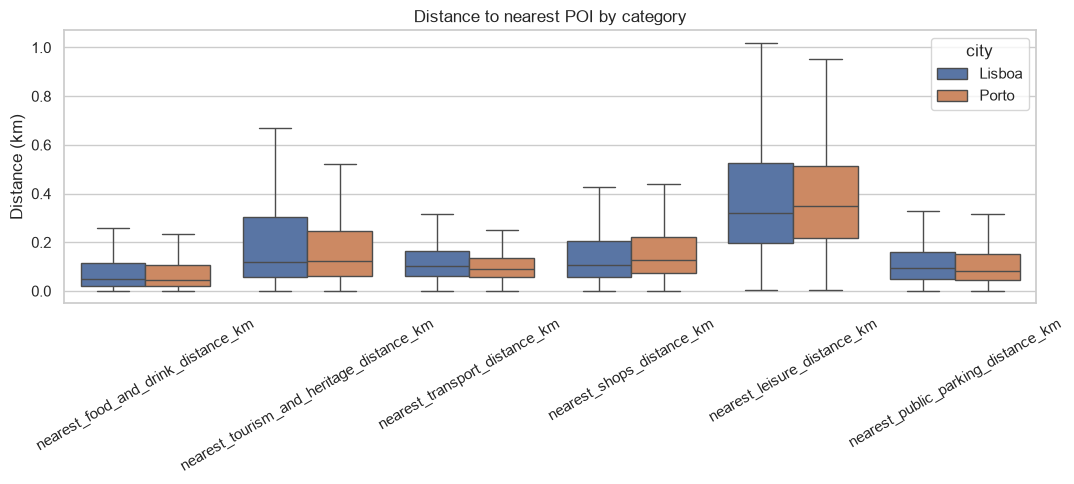

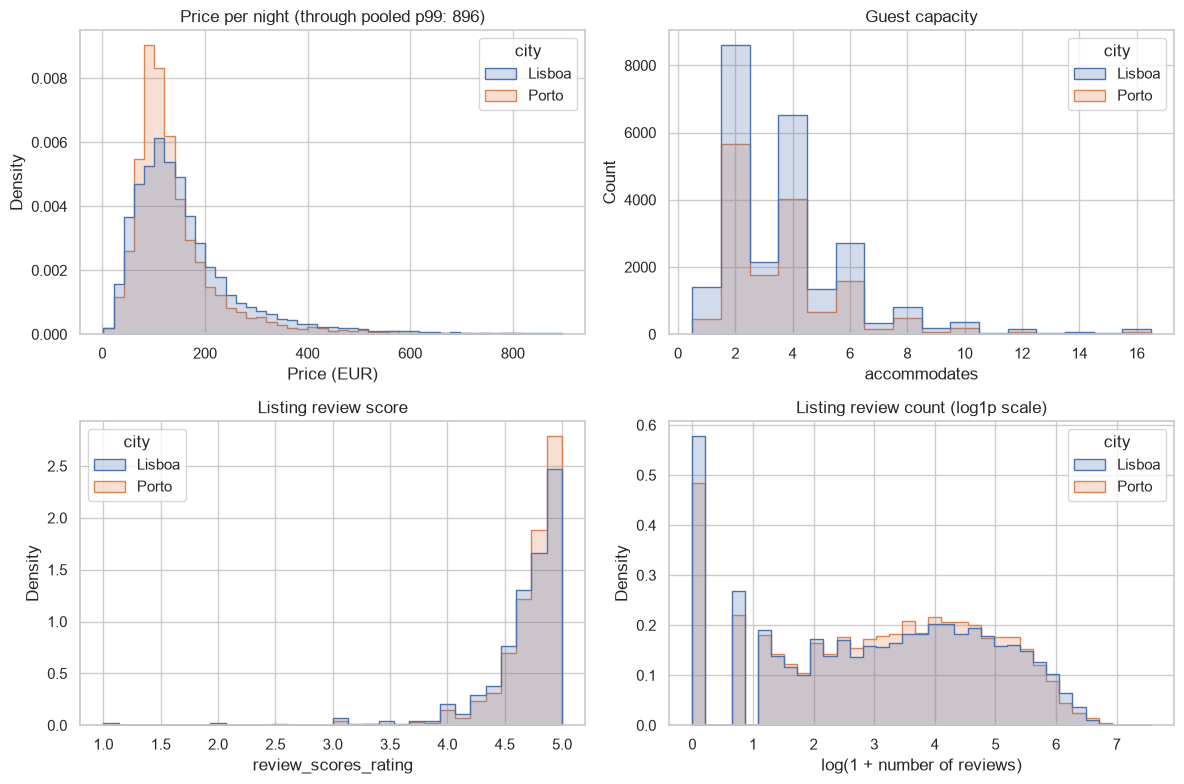

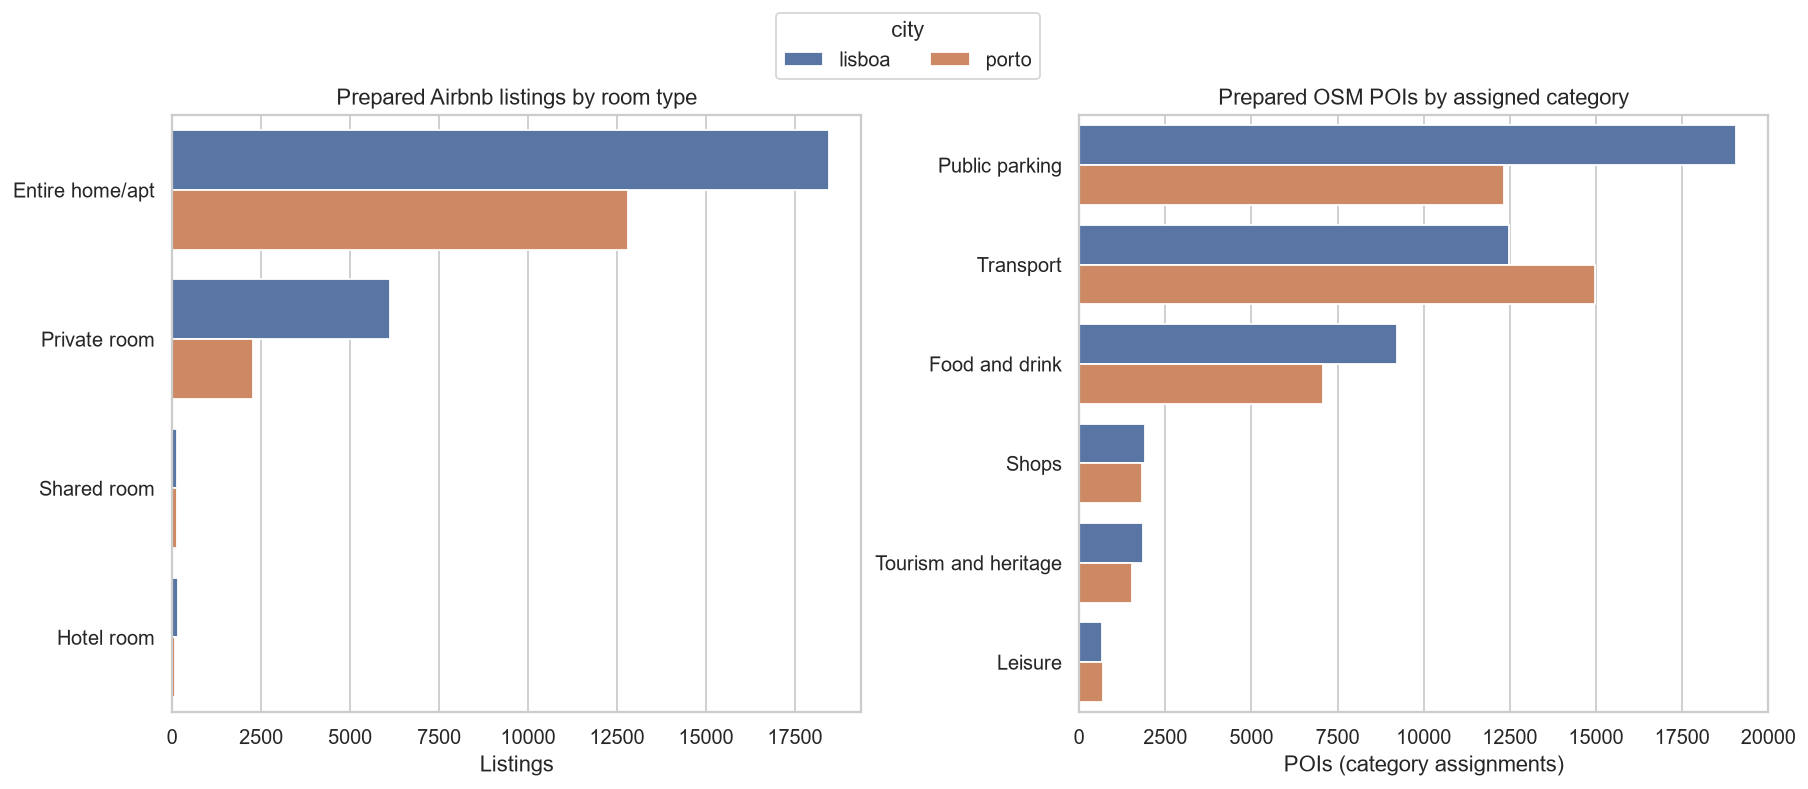

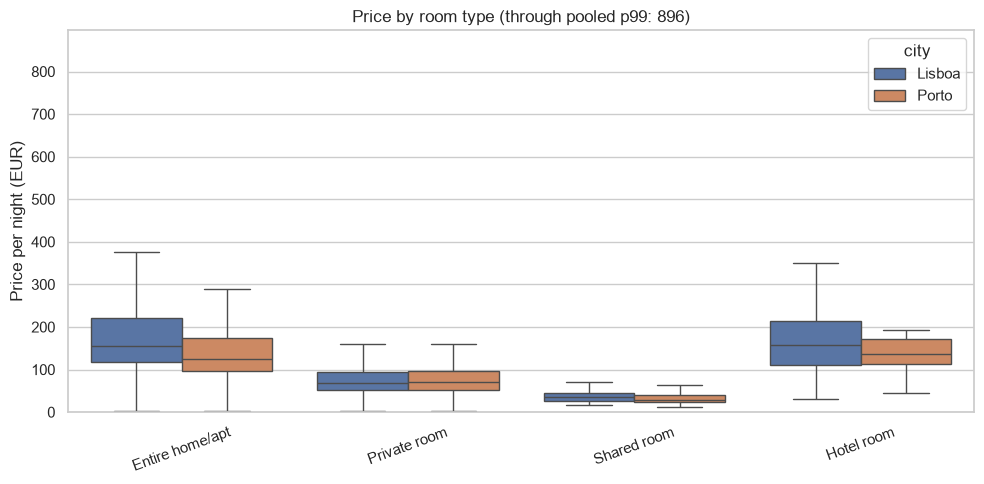

,city,variable,count,mean,median,q1,q3,p95,min,max
0,lisboa,price,22636,189.788905,136.00,92.0000,200.0000,442.0625,3.67,16077.50
1,lisboa,accommodates,24876,3.801656,4.00,2.0000,4.0000,8.0000,1.00,16.00
2,lisboa,bathrooms,21161,1.484736,1.00,1.0000,2.0000,3.0000,0.50,23.00
3,lisboa,bedrooms,20418,1.859585,2.00,1.0000,2.0000,4.0000,0.00,43.00
4,lisboa,beds,22367,2.437743,2.00,1.0000,3.0000,6.0000,1.00,45.00
5,lisboa,number_of_reviews,24876,75.845675,24.00,3.0000,96.0000,335.0000,0.00,1931.00
6,lisboa,number_of_reviews_ltm,24876,13.527939,6.00,1.0000,21.0000,50.0000,0.00,401.00
7,lisboa,availability_365,24876,223.750482,263.00,132.0000,323.0000,362.0000,0.00,365.00
8,lisboa,review_scores_rating,21766,4.660544,4.77,4.5700,4.9100,5.0000,1.00,5.00
9,lisboa,reviews_per_month,21766,1.529317,1.04,0.3600,2.2900,4.3900,0.01,27.86


,city,processed_listings,listings_with_reviews,listings_without_reviews,review_listing_ids_not_in_listings,median_reviews_per_reviewed_listing,p95_reviews_per_reviewed_listing,max_reviews_per_listing
0,lisboa,24876,21766,3110,28,35.0,353.0,1931
1,porto,15278,13676,1602,7,35.0,322.0,1137


,language,articles
0,pt,766
1,en,16


In [4]:
numeric_columns = [
    "price", "accommodates", "bathrooms", "bedrooms", "beds", "number_of_reviews",
    "number_of_reviews_ltm", "availability_365", "review_scores_rating", "reviews_per_month",
]
numeric_rows = []
for city, df in listings.items():
    for column in numeric_columns:
        if column not in df.columns:
            continue
        values = pd.to_numeric(df[column], errors="coerce").dropna()
        if values.empty:
            continue
        numeric_rows.append({
            "city": city, "variable": column, "count": int(values.size),
            "mean": float(values.mean()), "median": float(values.median()),
            "q1": float(values.quantile(0.25)), "q3": float(values.quantile(0.75)),
            "p95": float(values.quantile(0.95)), "min": float(values.min()), "max": float(values.max()),
        })
numeric_summary = pd.DataFrame(numeric_rows)
numeric_summary.to_csv(TABLES / "processed_airbnb_numeric_summary.csv", index=False)

distance_columns = [column for column in spatial_listings["lisboa"].columns
                    if column.startswith("nearest_") and column.endswith("_distance_km")]
distance_rows = []
for city, df in spatial_listings.items():
    for column in distance_columns:
        values = pd.to_numeric(df[column], errors="coerce").dropna()
        if not values.empty:
            distance_rows.append({"city": city, "variable": column, "count": int(values.size),
                                 "median_km": float(values.median()), "p95_km": float(values.quantile(0.95)),
                                 "max_km": float(values.max())})
distance_summary = pd.DataFrame(distance_rows)
distance_summary.to_csv(TABLES / "processed_nearest_poi_distance_summary.csv", index=False)
if not distance_summary.empty:
    fig, ax = plt.subplots(figsize=(11, 5))
    sns.boxplot(data=pd.concat([df.assign(city=city.title())[["city"] + distance_columns]
                                for city, df in spatial_listings.items()], ignore_index=True)
                   .melt(id_vars="city", var_name="poi_category", value_name="distance_km"),
                x="poi_category", y="distance_km", hue="city", showfliers=False, ax=ax)
    ax.set_title("Distance to nearest POI by category")
    ax.set_xlabel("")
    ax.set_ylabel("Distance (km)")
    ax.tick_params(axis="x", rotation=30)
    fig.tight_layout()
    fig.savefig(FIGURES / "processed_nearest_poi_distances.pdf", bbox_inches="tight")
    plt.show()

room_type_rows, neighbourhood_rows, osm_category_rows, element_type_rows = [], [], [], []
for city, df in listings.items():
    if "room_type" in df:
        room_type_rows.extend({"city": city, "room_type": label, "listings": int(count)}
                              for label, count in df["room_type"].fillna("(missing)").value_counts().items())
    if "neighbourhood_cleansed" in df:
        neighbourhood_rows.extend({"city": city, "neighbourhood": label, "listings": int(count)}
                                   for label, count in df["neighbourhood_cleansed"].fillna("(missing)").value_counts().head(20).items())
for city, df in osm.items():
    category_assignments = df["categories"].fillna("").astype(str).str.split(";").explode().str.strip()
    category_assignments = category_assignments[category_assignments.ne("")]
    osm_category_rows.extend({"city": city, "category": label, "pois": int(count)}
                              for label, count in category_assignments.value_counts().items())
    element_type_rows.extend({"city": city, "element_type": label, "pois": int(count)}
                              for label, count in df["element_type"].fillna("(missing)").value_counts().items())
room_type_counts = pd.DataFrame(room_type_rows)
neighbourhood_counts = pd.DataFrame(neighbourhood_rows)
osm_categories = pd.DataFrame(osm_category_rows)
osm_element_types = pd.DataFrame(element_type_rows)
wikipedia_languages = wikipedia.get("lang", pd.Series(dtype="object")).fillna("(missing)").value_counts().rename_axis("language").reset_index(name="articles")

room_type_counts.to_csv(TABLES / "processed_room_type_counts.csv", index=False)
neighbourhood_counts.to_csv(TABLES / "processed_top_neighbourhoods.csv", index=False)
osm_categories.to_csv(TABLES / "processed_osm_categories.csv", index=False)
osm_element_types.to_csv(TABLES / "processed_osm_element_types.csv", index=False)
wikipedia_languages.to_csv(TABLES / "processed_wikipedia_languages.csv", index=False)

review_coverage_rows, reviews_per_listing_rows = [], []
for city in CITIES:
    valid_ids = set(listings[city]["id"].dropna().astype(str))
    counts = review_listing_counts[city]
    valid_counts = np.array([count for listing_id, count in counts.items() if listing_id in valid_ids], dtype=np.int64)
    n_with_reviews = len(valid_counts)
    review_coverage_rows.append({
        "city": city, "processed_listings": len(valid_ids), "listings_with_reviews": n_with_reviews,
        "listings_without_reviews": len(valid_ids) - n_with_reviews,
        "review_listing_ids_not_in_listings": sum(listing_id not in valid_ids for listing_id in counts),
        "median_reviews_per_reviewed_listing": float(np.median(valid_counts)) if len(valid_counts) else np.nan,
        "p95_reviews_per_reviewed_listing": float(np.quantile(valid_counts, 0.95)) if len(valid_counts) else np.nan,
        "max_reviews_per_listing": int(valid_counts.max()) if len(valid_counts) else 0,
    })
    reviews_per_listing_rows.extend({"city": city, "reviews": int(count)} for count in valid_counts)
review_coverage = pd.DataFrame(review_coverage_rows)
review_coverage.to_csv(TABLES / "processed_review_coverage.csv", index=False)

plot_frames = []
for city, df in listings.items():
    part = df[[column for column in ["price", "accommodates", "number_of_reviews", "review_scores_rating"] if column in df]].copy()
    part["city"] = city.title()
    plot_frames.append(part)
plot_data = pd.concat(plot_frames, ignore_index=True)
plot_data["price"] = pd.to_numeric(plot_data.get("price"), errors="coerce")
plot_data["accommodates"] = pd.to_numeric(plot_data.get("accommodates"), errors="coerce")
plot_data["review_scores_rating"] = pd.to_numeric(plot_data.get("review_scores_rating"), errors="coerce")
plot_data["log1p_reviews"] = np.log1p(pd.to_numeric(plot_data.get("number_of_reviews"), errors="coerce"))
price_cap = plot_data["price"].quantile(0.99)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
sns.histplot(data=plot_data[plot_data["price"].le(price_cap)], x="price", hue="city", bins=45,
             stat="density", common_norm=False, element="step", ax=axes[0, 0])
axes[0, 0].set_title(f"Price per night (through pooled p99: {price_cap:.0f})")
axes[0, 0].set_xlabel("Price (EUR)")
sns.histplot(data=plot_data, x="accommodates", hue="city", discrete=True, common_norm=False,
             element="step", ax=axes[0, 1])
axes[0, 1].set_title("Guest capacity")
sns.histplot(data=plot_data, x="review_scores_rating", hue="city", bins=30,
             stat="density", common_norm=False, element="step", ax=axes[1, 0])
axes[1, 0].set_title("Listing review score")
sns.histplot(data=plot_data, x="log1p_reviews", hue="city", bins=35,
             stat="density", common_norm=False, element="step", ax=axes[1, 1])
axes[1, 1].set_title("Listing review count (log1p scale)")
axes[1, 1].set_xlabel("log(1 + number of reviews)")
fig.tight_layout()
fig.savefig(FIGURES / "processed_airbnb_distributions.pdf", bbox_inches="tight")
plt.show()

room_type_order = (room_type_counts.groupby("room_type")["listings"].sum()
                   .sort_values(ascending=False).index.tolist())
osm_categories["category_label"] = osm_categories["category"].str.replace("_", " ", regex=False).str.capitalize()
osm_category_order = (osm_categories.groupby("category_label")["pois"].sum()
                      .sort_values(ascending=False).index.tolist())
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(data=room_type_counts, y="room_type", x="listings", hue="city",
            order=room_type_order, ax=axes[0])
axes[0].set_title("Prepared Airbnb listings by room type")
axes[0].set_xlabel("Listings")
axes[0].set_ylabel("")
sns.barplot(data=osm_categories, y="category_label", x="pois", hue="city",
            order=osm_category_order, ax=axes[1])
axes[1].set_title("Prepared OSM POIs by assigned category")
axes[1].set_xlabel("POIs (category assignments)")
axes[1].set_ylabel("")
handles, labels = axes[0].get_legend_handles_labels()
for axis in axes:
    axis.legend_.remove()
fig.legend(handles, labels, title="city", loc="upper center", ncol=2,
           bbox_to_anchor=(0.5, 1.02))
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(FIGURES / "processed_categories.pdf", bbox_inches="tight")
plt.show()

price_room = pd.concat([df.assign(city=city.title())[["city", "room_type", "price"]] for city, df in listings.items()], ignore_index=True)
price_room["price"] = pd.to_numeric(price_room["price"], errors="coerce")
room_cap = price_room["price"].quantile(0.99)
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=price_room[price_room["price"].le(room_cap)], x="room_type", y="price", hue="city", showfliers=False, ax=ax)
ax.set_ylim(0, room_cap)
ax.set_title(f"Price by room type (through pooled p99: {room_cap:.0f})")
ax.set_xlabel("")
ax.set_ylabel("Price per night (EUR)")
ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
fig.savefig(FIGURES / "processed_price_by_room_type.pdf", bbox_inches="tight")
plt.show()

display(numeric_summary)
display(review_coverage)
display(wikipedia_languages)

## 5. Spatial overview

The maps use only processed listing coordinates, the processed spatial classification, and processed OSM POI coordinates. Listing coordinates are anonymized by the provider, and the prepared spatial files retain listings outside the municipal boundaries; use these maps to inspect broad coverage, not exact accommodation locations. The OSM extracts cover the downloaded query areas and may not contain every real-world POI.

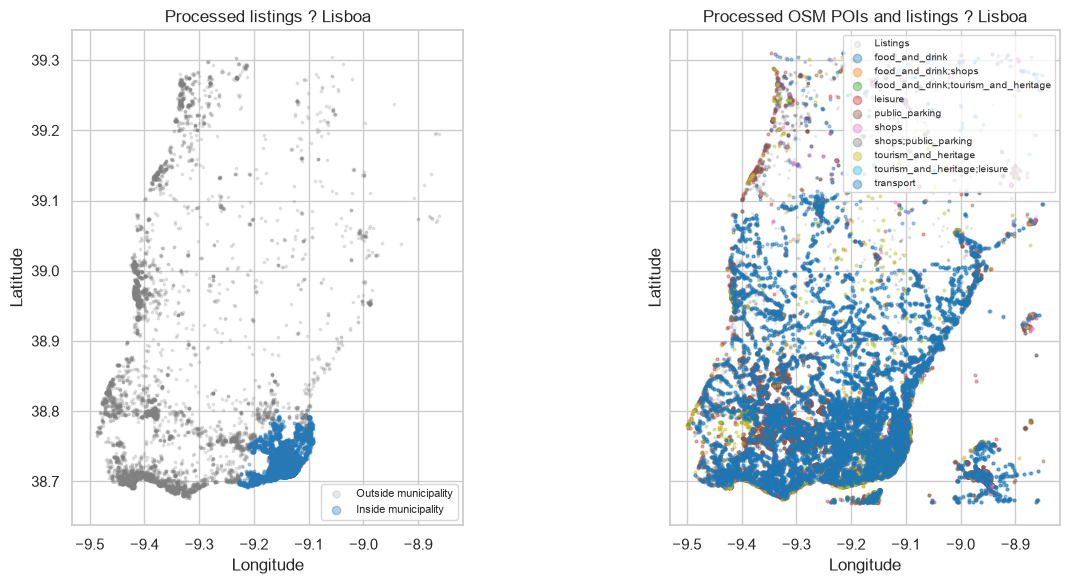

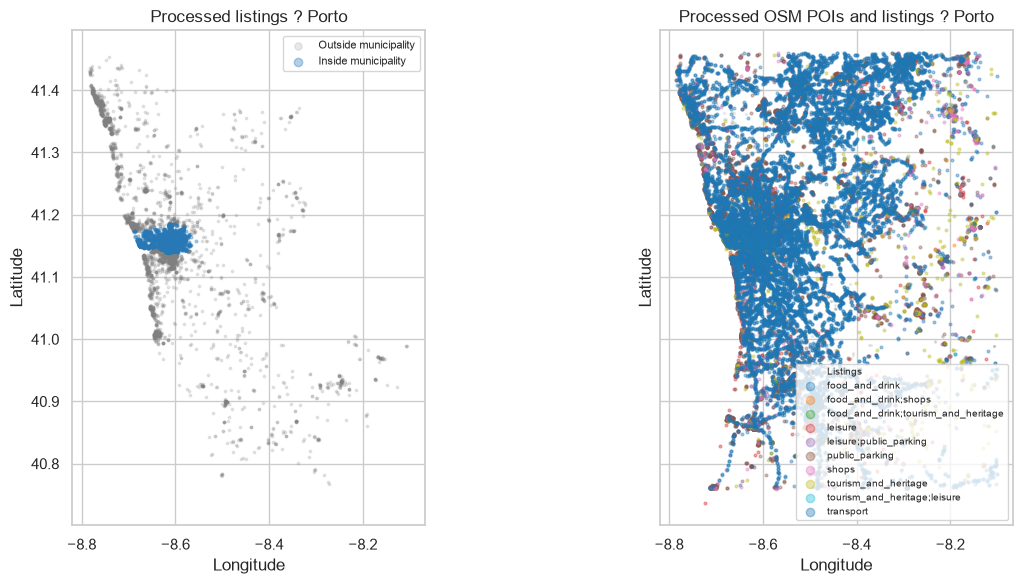

In [5]:
category_order = sorted(set(pd.concat([df["categories"].dropna() for df in osm.values()]).astype(str)))
palette = dict(zip(category_order, sns.color_palette("tab10", n_colors=max(len(category_order), 1))))
for city in CITIES:
    listing_map = spatial_listings[city].dropna(subset=["latitude", "longitude"]).copy()
    poi_map = osm[city].dropna(subset=["latitude", "longitude"]).copy()
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6), sharex=True, sharey=True)
    inside = listing_map.get("inside_city_municipality", pd.Series(False, index=listing_map.index)).fillna(False).astype(bool)
    ax1.scatter(listing_map.loc[~inside, "longitude"], listing_map.loc[~inside, "latitude"],
                s=3, alpha=0.18, color="grey", label="Outside municipality")
    ax1.scatter(listing_map.loc[inside, "longitude"], listing_map.loc[inside, "latitude"],
                s=4, alpha=0.35, color="#2878B5", label="Inside municipality")
    ax1.set_title(f"Processed listings ? {city.title()}")
    ax1.legend(markerscale=3, fontsize=8)
    ax2.scatter(listing_map["longitude"], listing_map["latitude"], s=2, alpha=0.12,
                color="grey", label="Listings")
    for category, points in poi_map.groupby("categories", dropna=False):
        label = str(category) if pd.notna(category) else "(missing)"
        ax2.scatter(points["longitude"], points["latitude"], s=4, alpha=0.38,
                    color=palette.get(str(category), "black"), label=label)
    ax2.set_title(f"Processed OSM POIs and listings ? {city.title()}")
    ax2.legend(markerscale=3, fontsize=7, loc="best")
    for ax in (ax1, ax2):
        ax.set_xlabel("Longitude")
        ax.set_ylabel("Latitude")
        ax.set_aspect(1 / np.cos(np.deg2rad(listing_map["latitude"].mean())))
    fig.tight_layout()
    fig.savefig(FIGURES / f"processed_spatial_overview_{city}.pdf", bbox_inches="tight")
    plt.show()

## 6. Text and final-record document metrics

The document metrics table reports counts and word/character length statistics for each processed text-bearing source. Reviews are measured across all records; no review language classification is attempted here. The text-length plot samples review rows to keep rendering quick, while the tabulated review metrics above remain exact for the full files.

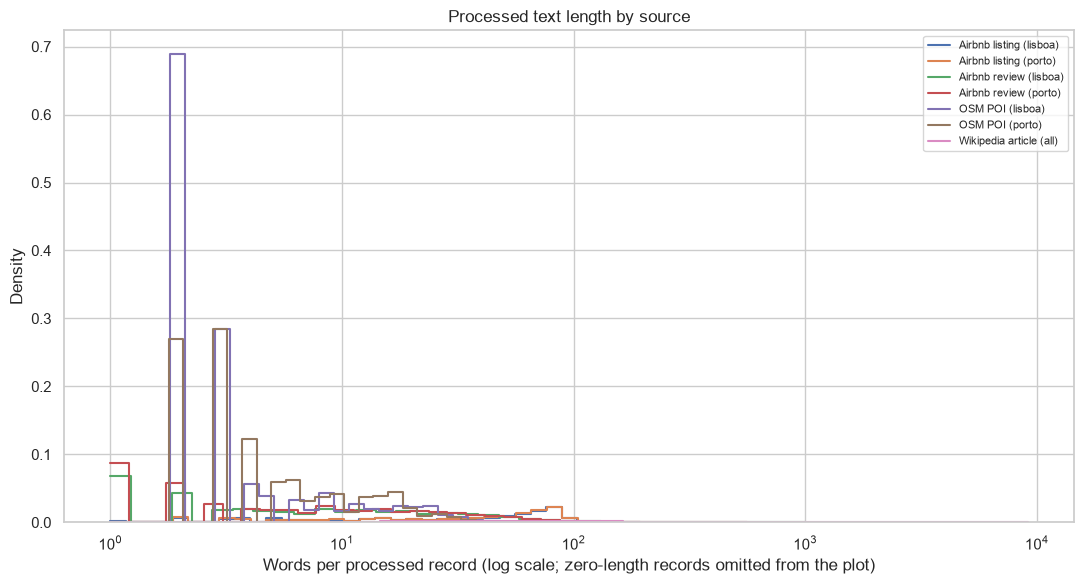

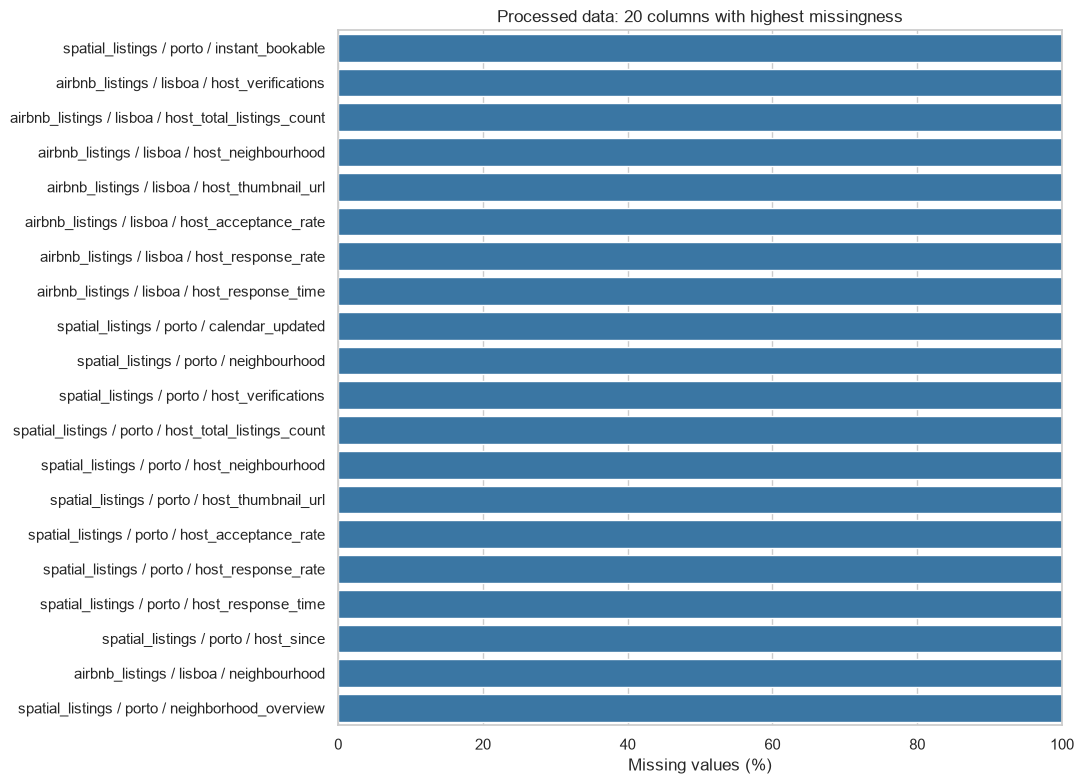

,source,city,documents,missing_text,empty_text,mean_chars,median_chars,p95_chars,mean_words,median_words,p95_words,max_words
0,Airbnb listing,lisboa,24876,0,0,389.885311,433.0,542.00,64.900587,71.0,93.00,193
1,Airbnb listing,porto,15278,0,0,386.484946,425.0,537.00,64.672143,70.0,93.00,194
5,Airbnb review,lisboa,1886932,140,140,258.496025,195.0,724.00,44.581880,33.0,127.00,1002
6,Airbnb review,porto,1131143,69,69,235.006822,177.0,657.00,40.415869,30.0,115.00,1000
2,OSM POI,lisboa,45159,0,0,102.282889,72.0,292.00,13.611218,10.0,36.00,154
3,OSM POI,porto,38390,0,0,90.726700,73.0,203.00,12.279187,10.0,30.00,140
4,Wikipedia article,all,782,0,0,3698.632992,2191.0,12977.15,599.648338,359.0,2003.95,9166


In [6]:
text_samples = {}
for key, values in document_word_samples.items():
    text_samples[key] = np.asarray(values, dtype=np.int32)
for city, values in review_length_samples.items():
    text_samples[("Airbnb review", city)] = values

plot_rows = []
for (source, city), lengths in text_samples.items():
    if len(lengths) == 0:
        continue
    if len(lengths) > 50_000:
        rng = np.random.default_rng(SEED)
        lengths = rng.choice(lengths, size=50_000, replace=False)
    plot_rows.extend({"source": source, "city": city, "words": int(value)} for value in lengths)
text_plot = pd.DataFrame(plot_rows)

fig, ax = plt.subplots(figsize=(11, 6))
for (source, city), group in text_plot.groupby(["source", "city"]):
    nonzero = group.loc[group["words"].gt(0), "words"]
    if len(nonzero):
        sns.histplot(nonzero, bins=np.logspace(0, np.log10(max(nonzero.max(), 2)), 35),
                     stat="density", element="step", fill=False, ax=ax,
                     label=f"{source} ({city})")
ax.set_xscale("log")
ax.set_xlabel("Words per processed record (log scale; zero-length records omitted from the plot)")
ax.set_ylabel("Density")
ax.set_title("Processed text length by source")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "processed_text_lengths.pdf", bbox_inches="tight")
plt.show()

top_missing = missing_values.sort_values("missing_pct", ascending=False).head(20).copy()
top_missing["label"] = top_missing["dataset"] + " / " + top_missing["city"] + " / " + top_missing["column"]
fig, ax = plt.subplots(figsize=(11, 8))
sns.barplot(data=top_missing, y="label", x="missing_pct", color="#2878B5", ax=ax)
ax.set_xlim(0, 100)
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("")
ax.set_title("Processed data: 20 columns with highest missingness")
fig.tight_layout()
fig.savefig(FIGURES / "processed_missing_values_top20.pdf", bbox_inches="tight")
plt.show()

display(document_metrics.sort_values(["source", "city"]))

## 7. Summary and interpretation notes

**Comparison with `01_eda.ipynb`:** raw and processed profiles describe different stages, so normalized text/price fields and OSM category totals can differ. Airbnb listing and review row counts currently match between stages; the prepared listing files add four provenance/preparation fields. The prepared OSM categories can assign multiple labels to one POI, and this chart counts assignments. Also, the saved raw EDA outputs do not match the current inputs: they report OSM totals of 45,150 / 38,411 and 787 Wikipedia articles, while the current raw files contain 45,159 / 38,390 POIs and 782 Wikipedia records. The saved raw review coverage counts 28 Lisbon and 7 Porto review IDs that do not match a listing; the processed coverage reports matched listing IDs separately.



In [7]:
listing_totals = {city: len(df) for city, df in listings.items()}
review_totals = {city: review_rows_by_city[city] for city in CITIES}
poi_totals = {city: len(df) for city, df in osm.items()}
print("Processed source volumes")
for city in CITIES:
    print(f"{city.title()}: {listing_totals[city]:,} listings; {review_totals[city]:,} reviews; {poi_totals[city]:,} OSM POIs")
print(f"Wikipedia: {len(wikipedia):,} articles")
print(f"Spatial listing files: {sum(len(df) for df in spatial_listings.values()):,} rows")
print("\nInterpretation notes:")
print("- Missing values describe the prepared snapshot; a missing field may be unavailable or inapplicable rather than erroneous.")
print("- Price plots are clipped at the 99th percentile for readability; the numeric CSV retains observed minimums and maximums.")
print("- Listing coordinates are anonymized and spatial files include records outside city municipalities.")
print("- OSM coverage is limited to the downloaded extract; absent POIs or names do not prove real-world absence.")
print("- Document metrics use processed source records as document proxies because no consolidated final-document file is currently present.")

Processed source volumes
Lisboa: 24,876 listings; 1,886,932 reviews; 45,159 OSM POIs
Porto: 15,278 listings; 1,131,143 reviews; 38,390 OSM POIs
Wikipedia: 782 articles
Spatial listing files: 40,154 rows

Interpretation notes:
- Missing values describe the prepared snapshot; a missing field may be unavailable or inapplicable rather than erroneous.
- Price plots are clipped at the 99th percentile for readability; the numeric CSV retains observed minimums and maximums.
- Listing coordinates are anonymized and spatial files include records outside city municipalities.
- OSM coverage is limited to the downloaded extract; absent POIs or names do not prove real-world absence.
- Document metrics use processed source records as document proxies because no consolidated final-document file is currently present.
